In [1]:
import sys
from pathlib import Path
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
PROJECT_ROOT = Path.cwd().parent
SRC_DIR = PROJECT_ROOT / "src"

if str(SRC_DIR) not in sys.path:
    sys.path.append(str(SRC_DIR))
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
     roc_curve,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

# add original folder into PYTHONPATH
project_root = Path().resolve().parent   
sys.path.append(str(project_root))
from ml.churn_model.models.evaluate import (
    evaluate_classifier
)
from sklearn.tree import (
    DecisionTreeClassifier
)

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
)

from pathlib import Path

PROCESSED_DATA_DIR = Path("../data/processed")
# Load train/test datasets
X_train = pd.read_csv(
    PROCESSED_DATA_DIR / "X_train.csv"
)

X_test = pd.read_csv(
    PROCESSED_DATA_DIR / "X_test.csv"
)

y_train = pd.read_csv(
    PROCESSED_DATA_DIR / "y_train.csv"
).squeeze("columns")

y_test = pd.read_csv(
    PROCESSED_DATA_DIR / "y_test.csv"
).squeeze("columns")
#Verify Loaded Data
print("Dataset shapes")
print("-" * 40)

print(f"X_train: {X_train.shape}")
print(f"X_test : {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test : {y_test.shape}")
#Preview training data
X_train.head()
#Preview target
y_train.head()



Dataset shapes
----------------------------------------
X_train: (5634, 64)
X_test : (1409, 64)
y_train: (5634,)
y_test : (1409,)


0    0
1    0
2    0
3    0
4    0
Name: Churn, dtype: int64

In [2]:
#Check target distribution
print("Training target distribution:") 
print(y_train.value_counts())
print("\nTraining target ratio:") 
print(y_train.value_counts(normalize=True))

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Training target ratio:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64


In [3]:
import sys
from pathlib import Path

# add original folder into PYTHONPATH
project_root = Path().resolve().parent   
sys.path.append(str(project_root))

print("Project root:", project_root)


#Build Logistic Regression Pipeline
logistic_model =  LogisticRegression( max_iter=1000, random_state=42, )
     

#Train Logistic Regression
logistic_model.fit( X_train, y_train, )

Project root: D:\Research_Project\customer-churn-prediction


,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [4]:
#Generate Logistic Regression Predictions
#Predicted classes
y_pred_logistic = logistic_model.predict( X_test )
#Predicted churn probabilities
y_prob_logistic = logistic_model.predict_proba( X_test )[:, 1]
#Preview predictions
print("First 10 predictions:") 
print(y_pred_logistic[:10])

print("\nFirst 10 actual values:") 
print(y_test.iloc[:10].values)

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

First 10 actual values:
[0 0 0 0 0 0 0 0 0 1]


In [5]:
#Logistic Regression Metrics
logistic_metrics = evaluate_classifier(
    "Logistic Regression",
    y_test,
    y_pred_logistic,
    y_prob_logistic,
)

pd.DataFrame([logistic_metrics])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.797019,0.646667,0.518717,0.575668,0.841975,0.635763


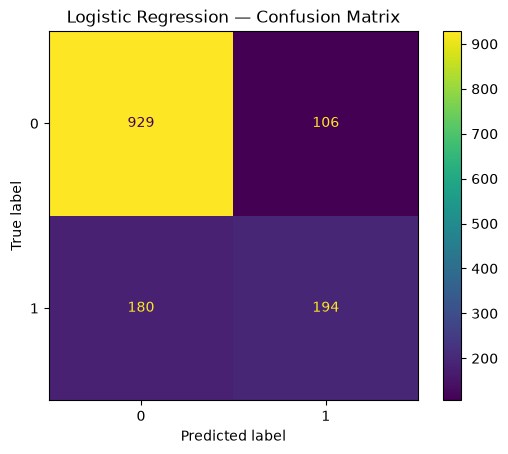

In [6]:
#Logistic Regression Confusion Matrix
ConfusionMatrixDisplay.from_predictions( 
    y_test, 
    y_pred_logistic )
plt.title( "Logistic Regression — Confusion Matrix" )
plt.show()

In [7]:
#Extract confusion matrix values
logistic_cm = confusion_matrix( y_test, y_pred_logistic, )
tn, fp, fn, tp = logistic_cm.ravel() 
print(f"True Negative (TN): {tn}") 
print(f"False Positive (FP): {fp}") 
print(f"False Negative (FN): {fn}") 
print(f"True Positive (TP): {tp}")

True Negative (TN): 929
False Positive (FP): 106
False Negative (FN): 180
True Positive (TP): 194


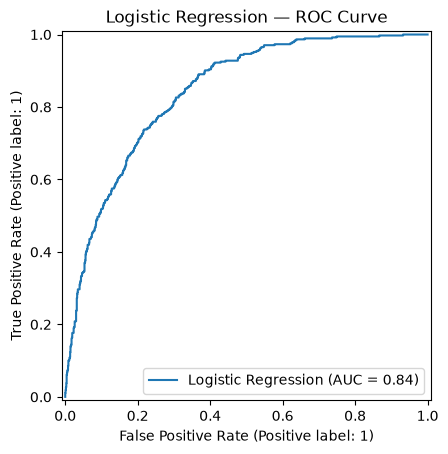

In [8]:
#Logistic Regression ROC Curve
RocCurveDisplay.from_predictions( 
    y_test, 
    y_prob_logistic, 
    name="Logistic Regression", )
plt.title( "Logistic Regression — ROC Curve" )
plt.show()

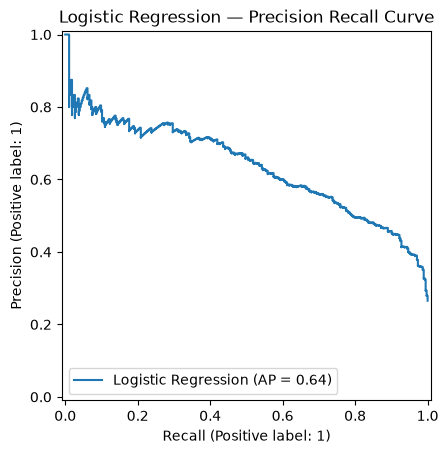

In [9]:
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_logistic,
    name="Logistic Regression",
)

plt.title(
    "Logistic Regression — Precision Recall Curve"
)

plt.show()

In [10]:
#ROC-AUC score
logistic_auc = roc_auc_score( 
    y_test, 
    y_prob_logistic, )
print( f"Logistic Regression ROC-AUC: " f"{logistic_auc:.4f}" )

Logistic Regression ROC-AUC: 0.8420


In [11]:

random_forest_model =  RandomForestClassifier( 
            n_estimators=200, 
            random_state=42, 
            n_jobs=-1, )
      
#Train Random Forest
random_forest_model.fit( 
    X_train, 
    y_train, )

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [12]:
#Generate Random Forest Predictions
y_pred_rf = random_forest_model.predict( X_test 
 ) 

y_prob_rf = random_forest_model.predict_proba( 
    X_test )[:, 1]
#Random Forest Classification Report
print( classification_report( 
    y_test, 
    y_pred_rf))

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.61      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [13]:
#Random Forest Metrics
rf_metrics = evaluate_classifier(
    "Random Forest",
    y_test,
    y_pred_rf,
    y_prob_rf,
)
pd.DataFrame([
    rf_metrics
])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.780696,0.607261,0.491979,0.543575,0.823377,0.61181


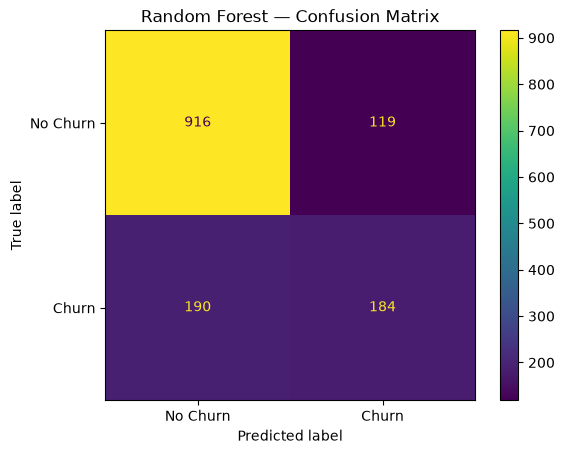

In [14]:
#Random Forest Confusion Matrix
ConfusionMatrixDisplay.from_predictions( 
    y_test, 
    y_pred_rf, 
    display_labels=[ "No Churn", "Churn", ], 
    )
plt.title( "Random Forest — Confusion Matrix" )
plt.show()

In [15]:
#Extract confusion matrix values
rf_cm = confusion_matrix( y_test, y_pred_rf, ) 
tn_rf, fp_rf, fn_rf, tp_rf = rf_cm.ravel()
print(f"True Negative (TN): {tn_rf}") 
print(f"False Positive (FP): {fp_rf}") 
print(f"False Negative (FN): {fn_rf}") 
print(f"True Positive (TP): {tp_rf}")

True Negative (TN): 916
False Positive (FP): 119
False Negative (FN): 190
True Positive (TP): 184


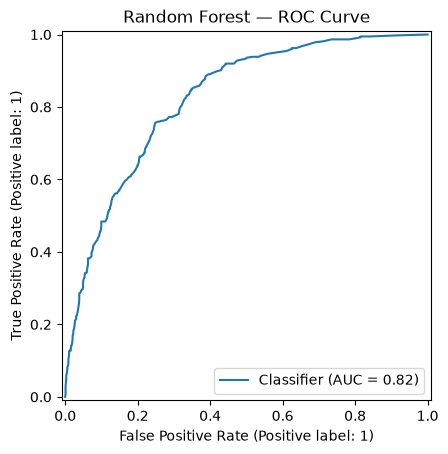

In [16]:
#Random Forest ROC Curve
RocCurveDisplay.from_predictions( 
    y_test, 
    y_prob_rf)
plt.title( "Random Forest — ROC Curve" )
plt.show()

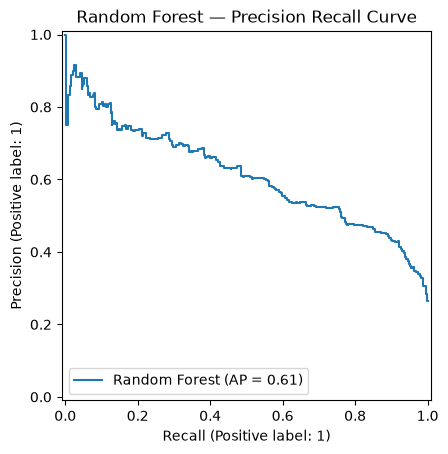

In [17]:
#PR Curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest",
)

plt.title(
    "Random Forest — Precision Recall Curve"
)

plt.show()

In [18]:
#Decision Tree
decision_tree_model = (
    DecisionTreeClassifier(
        max_depth=5,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
    )
)

decision_tree_model.fit(
    X_train,
    y_train,
)
#Prediction
y_pred_dt = (
    decision_tree_model.predict(
        X_test
    )
)

y_prob_dt = (
    decision_tree_model.predict_proba(
        X_test
    )[:, 1]
)
#Metrics
dt_metrics = evaluate_classifier(
    "Decision Tree",
    y_test,
    y_pred_dt,
    y_prob_dt,
)

pd.DataFrame([
    dt_metrics
])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Decision Tree,0.791341,0.60929,0.596257,0.602703,0.825904,0.616716


In [19]:
#Gradient Boosting
gradient_boosting_model = (
    GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
    )
)

gradient_boosting_model.fit(
    X_train,
    y_train,
)
#Predict
y_pred_gb = (
    gradient_boosting_model.predict(
        X_test
    )
)

y_prob_gb = (
    gradient_boosting_model
    .predict_proba(
        X_test
    )[:, 1]
)
#Evaluate
gb_metrics = evaluate_classifier(
    "Gradient Boosting",
    y_test,
    y_pred_gb,
    y_prob_gb,
)

pd.DataFrame([
    gb_metrics
])

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Gradient Boosting,0.807665,0.687273,0.505348,0.582435,0.847193,0.661443


In [20]:
#Model Comparison
#Compare baseline models
baseline_results = pd.DataFrame( [ 
    logistic_metrics, 
    dt_metrics,
    rf_metrics,
    gb_metrics, ] )
baseline_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,0.797019,0.646667,0.518717,0.575668,0.841975,0.635763
1,Decision Tree,0.791341,0.609290,0.596257,0.602703,0.825904,0.616716
2,Random Forest,0.780696,0.607261,0.491979,0.543575,0.823377,0.611810
3,Gradient Boosting,0.807665,0.687273,0.505348,0.582435,0.847193,0.661443


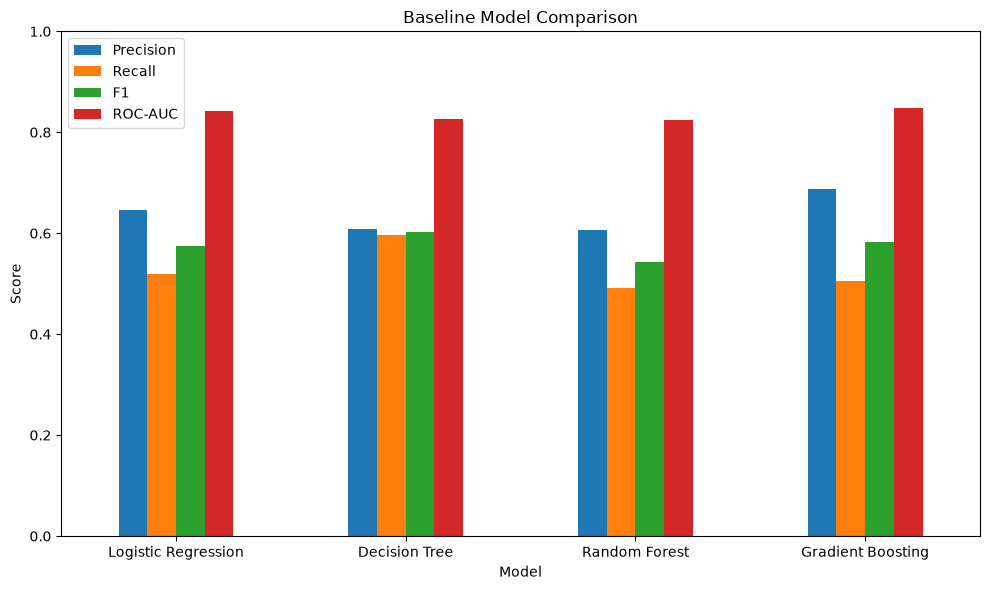

In [21]:
baseline_results.sort_values(
    by="ROC-AUC",
    ascending=False,
).round(4)
baseline_results.set_index("Model")[
    [
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC",
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylim(0, 1)
plt.title("Baseline Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

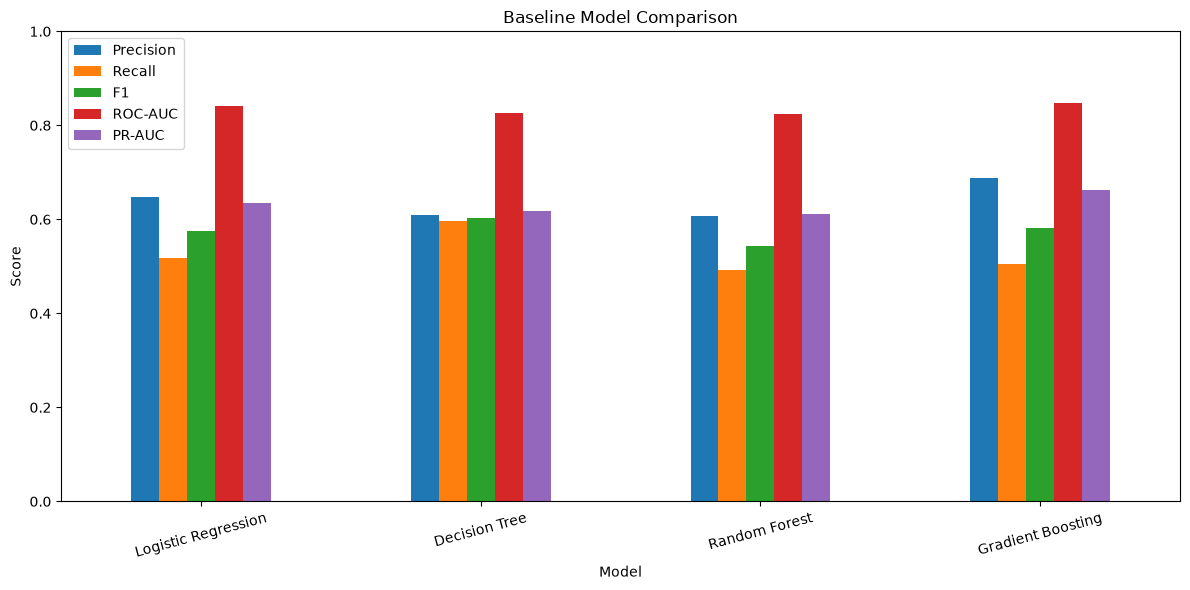

In [22]:
#Visualization model comparison
comparison_metrics = [
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "PR-AUC",
]

baseline_results.set_index(
    "Model"
)[
    comparison_metrics
].plot(
    kind="bar",
    figsize=(12, 6),
)

plt.ylim(0, 1)

plt.title(
    "Baseline Model Comparison"
)

plt.ylabel(
    "Score"
)

plt.xticks(
    rotation=15
)

plt.tight_layout()

plt.show()

In [23]:
from pathlib import Path

METRICS_DIR = Path(
    "../artifacts/metrics"
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)
#Save baseline metrics
baseline_results.to_csv(
    METRICS_DIR / "baseline_metrics.csv",
    index=False
)

## Baseline Model Findings

Two baseline classification models were evaluated:

- Logistic Regression
- Random Forest

The models were compared using:

- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Because the business objective is to identify customers at risk
of churn, recall for the churn class is particularly important.

False negatives represent customers who actually churn but are not
identified by the model, potentially preventing the business from
taking proactive retention actions.

The baseline results will be used as a benchmark for subsequent
model optimization and advanced machine learning experiments.